# AI Customer Support Intelligence
## BANKING77 Intent Classification — Model Training & Evaluation

### Objectives
- Train Logistic Regression, Linear SVM, Random Forest and XGBoost.
- Compare Accuracy, Macro F1-score and Weighted F1-score.
- Select the best model using validation Macro F1-score.
- Evaluate the selected model on the official test dataset.
- Save the trained model for future chatbot integration.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
)

import joblib

warnings.filterwarnings("ignore", category=UserWarning)

# Detect project root
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

REPORT_DIR = ROOT / "reports" / "models"
MODEL_DIR = ROOT / "models" / "intent_classification"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

# XGBoost is optional until its package is installed
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

print("Project root:", ROOT)
print("XGBoost available:", XGBOOST_AVAILABLE)
print("Model output directory:", MODEL_DIR)

Project root: d:\Data scientist\AI Customer Support Intelligence
XGBoost available: True
Model output directory: d:\Data scientist\AI Customer Support Intelligence\models\intent_classification


In [2]:
TRAIN_PATH = ROOT / "data" / "processed" / "banking77" / "train.csv"
TEST_PATH = ROOT / "data" / "processed" / "banking77" / "test.csv"

if not TRAIN_PATH.exists():
    raise FileNotFoundError(f"Training file not found: {TRAIN_PATH}")

if not TEST_PATH.exists():
    raise FileNotFoundError(f"Test file not found: {TEST_PATH}")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

required_columns = {"text", "category"}

for name, df in [("train", train_df), ("test", test_df)]:
    if not required_columns.issubset(df.columns):
        raise ValueError(
            f"{name} dataset requires {required_columns}; "
            f"found {df.columns.tolist()}"
        )

# Defensive validation; cleaning should already have handled these.
train_df = train_df.dropna(subset=["text", "category"]).copy()
test_df = test_df.dropna(subset=["text", "category"]).copy()

for df in (train_df, test_df):
    df["text"] = df["text"].astype(str).str.strip()
    df["category"] = df["category"].astype(str).str.strip()

    df.drop(
        df[(df["text"] == "") | (df["category"] == "")].index,
        inplace=True,
    )

print("Training records:", f"{len(train_df):,}")
print("Testing records:", f"{len(test_df):,}")
print("Training categories:", train_df["category"].nunique())
print("Test categories:", test_df["category"].nunique())

display(train_df.head())
display(train_df["category"].value_counts().head(10))

Training records: 10,003
Testing records: 3,080
Training categories: 77
Test categories: 77


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
transaction_charged_twice                           175
declined_cash_withdrawal                            173
transfer_fee_charged                                172
transfer_not_received_by_recipient                  171
balance_not_updated_after_bank_transfer             171
Name: count, dtype: int64

In [3]:
X_text = train_df["text"].astype(str)
y = train_df["category"].astype(str)

# Consistent numeric encoding for models that require integer targets
label_encoder = LabelEncoder()
label_encoder.fit(y)

X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Model training samples:", f"{len(X_train_text):,}")
print("Validation samples:", f"{len(X_val_text):,}")

# TF-IDF converts text into numerical features
VECTORIZER_CONFIG = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_features": 50000,
    "sublinear_tf": True,
    "strip_accents": "unicode",
    "dtype": np.float32,
}

vectorizer = TfidfVectorizer(**VECTORIZER_CONFIG)

X_train_vec = vectorizer.fit_transform(X_train_text)
X_val_vec = vectorizer.transform(X_val_text)

print("Training feature matrix:", X_train_vec.shape)
print("Validation feature matrix:", X_val_vec.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Model training samples: 8,002
Validation samples: 2,001
Training feature matrix: (8002, 8903)
Validation feature matrix: (2001, 8903)
Vocabulary size: 8903


In [4]:
models = {
    "Logistic Regression": LogisticRegression(
        C=4.0,
        max_iter=1500,
        solver="lbfgs",
        random_state=RANDOM_STATE,
    ),

    "Linear SVM": LinearSVC(
        C=1.5,
        max_iter=3000,
        random_state=RANDOM_STATE,
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=80,
        max_depth=30,
        min_samples_leaf=2,
        max_features="sqrt",
        n_jobs=2,
        random_state=RANDOM_STATE,
    ),
}

if XGBOOST_AVAILABLE:
    models["XGBoost"] = XGBClassifier(
        n_estimators=50,
        max_depth=4,
        learning_rate=0.15,
        subsample=0.85,
        colsample_bytree=0.65,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        tree_method="hist",
        max_bin=128,
        n_jobs=2,
        random_state=RANDOM_STATE,
        verbosity=0,
    )

trained_models = {}
results = []

# XGBoost requires numeric class labels
y_train_encoded = label_encoder.transform(y_train)

for model_name, model in models.items():
    print(f"\nTraining: {model_name}")
    start_time = time.time()

    if model_name == "XGBoost":
        model.fit(X_train_vec, y_train_encoded)
        predictions_encoded = model.predict(X_val_vec).astype(int)
        predictions = label_encoder.inverse_transform(
            predictions_encoded
        )
    else:
        model.fit(X_train_vec, y_train)
        predictions = model.predict(X_val_vec)

    elapsed = time.time() - start_time

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val, predictions, average="macro", zero_division=0
    )
    weighted_f1 = f1_score(
        y_val, predictions, average="weighted", zero_division=0
    )

    trained_models[model_name] = model

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Training Time (seconds)": round(elapsed, 2),
    })

    print(f"Accuracy:   {accuracy:.4f}")
    print(f"Macro F1:   {macro_f1:.4f}")
    print(f"Weighted F1: {weighted_f1:.4f}")
    print(f"Training time: {elapsed:.2f} seconds")

print("\nAll available models have completed training.")


Training: Logistic Regression
Accuracy:   0.8726
Macro F1:   0.8743
Weighted F1: 0.8727
Training time: 14.97 seconds

Training: Linear SVM
Accuracy:   0.8806
Macro F1:   0.8817
Weighted F1: 0.8806
Training time: 0.85 seconds

Training: Random Forest
Accuracy:   0.7581
Macro F1:   0.7499
Weighted F1: 0.7552
Training time: 1.21 seconds

Training: XGBoost
Accuracy:   0.7956
Macro F1:   0.7963
Weighted F1: 0.7970
Training time: 70.41 seconds

All available models have completed training.


,Model,Accuracy,Macro F1,Weighted F1,Training Time (seconds)
0,Linear SVM,0.8806,0.8817,0.8806,0.85
1,Logistic Regression,0.8726,0.8743,0.8727,14.97
2,XGBoost,0.7956,0.7963,0.7970,70.41
3,Random Forest,0.7581,0.7499,0.7552,1.21


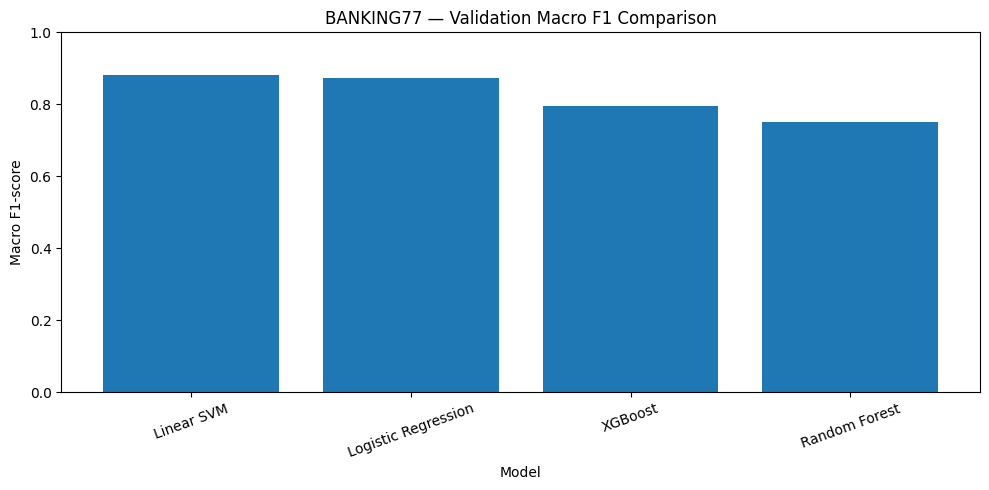

Best validation model: Linear SVM
Selected by: highest validation Macro F1-score


In [5]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False,
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Training Time (seconds)": "{:.2f}",
    })
)

results_df.to_csv(
    REPORT_DIR / "banking77_validation_results.csv",
    index=False,
)

# Compare validation Macro F1
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Macro F1"],
)

plt.title("BANKING77 — Validation Macro F1 Comparison")
plt.xlabel("Model")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "banking77_model_comparison.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

best_model_name = results_df.iloc[0]["Model"]

print("Best validation model:", best_model_name)
print("Selected by: highest validation Macro F1-score")

In [6]:
best_model = clone(trained_models[best_model_name])

# Fit a fresh vectorizer on the complete official training set
final_vectorizer = TfidfVectorizer(**VECTORIZER_CONFIG)

X_full_train_vec = final_vectorizer.fit_transform(
    train_df["text"].astype(str)
)

X_test_vec = final_vectorizer.transform(
    test_df["text"].astype(str)
)

y_full_train = train_df["category"].astype(str)
y_test = test_df["category"].astype(str)

if best_model_name == "XGBoost":
    y_full_train_encoded = label_encoder.transform(y_full_train)
    best_model.fit(X_full_train_vec, y_full_train_encoded)

    test_predictions_encoded = best_model.predict(
        X_test_vec
    ).astype(int)

    test_predictions = label_encoder.inverse_transform(
        test_predictions_encoded
    )
else:
    best_model.fit(X_full_train_vec, y_full_train)
    test_predictions = best_model.predict(X_test_vec)

print("Final model:", best_model_name)
print("Final training matrix:", X_full_train_vec.shape)
print("Official test matrix:", X_test_vec.shape)

Final model: Linear SVM
Final training matrix: (10003, 10292)
Official test matrix: (3080, 10292)


In [7]:
test_accuracy = accuracy_score(y_test, test_predictions)

test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0,
)

test_weighted_f1 = f1_score(
    y_test,
    test_predictions,
    average="weighted",
    zero_division=0,
)

test_metrics = {
    "best_model": best_model_name,
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(test_macro_f1),
    "test_weighted_f1": float(test_weighted_f1),
    "test_samples": int(len(y_test)),
}

print("Official test results")
print("-" * 35)
print(f"Accuracy:    {test_accuracy:.4f}")
print(f"Macro F1:    {test_macro_f1:.4f}")
print(f"Weighted F1: {test_weighted_f1:.4f}")

with (REPORT_DIR / "banking77_test_metrics.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(test_metrics, f, indent=2)

print("\nMetrics saved.")

Official test results
-----------------------------------
Accuracy:    0.8906
Macro F1:    0.8906
Weighted F1: 0.8906

Metrics saved.


In [8]:
all_categories = label_encoder.classes_.tolist()

report_dict = classification_report(
    y_test,
    test_predictions,
    labels=all_categories,
    target_names=all_categories,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).T

display(
    report_df.sort_values(
        by="f1-score",
        ascending=True,
    ).head(15)
)

report_df.to_csv(
    REPORT_DIR / "banking77_classification_report.csv"
)

with (REPORT_DIR / "banking77_classification_report.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(report_dict, f, indent=2)

# Save incorrectly classified test examples for error analysis
error_df = pd.DataFrame({
    "text": test_df["text"].astype(str).to_numpy(),
    "actual_intent": y_test.to_numpy(),
    "predicted_intent": np.asarray(test_predictions),
})

error_df = error_df[
    error_df["actual_intent"] != error_df["predicted_intent"]
]

error_df.to_csv(
    REPORT_DIR / "banking77_misclassified_examples.csv",
    index=False,
)

print("Misclassified examples:", len(error_df))
display(error_df.head(20))

,precision,recall,f1-score,support
balance_not_updated_after_bank_transfer,0.674419,0.725,0.698795,40.0
pending_transfer,0.812500,0.650,0.722222,40.0
verify_my_identity,0.769231,0.750,0.759494,40.0
transfer_not_received_by_recipient,0.727273,0.800,0.761905,40.0
wrong_exchange_rate_for_cash_withdrawal,0.805556,0.725,0.763158,40.0
top_up_failed,0.775000,0.775,0.775000,40.0
card_not_working,0.714286,0.875,0.786517,40.0
failed_transfer,0.739130,0.850,0.790698,40.0
top_up_reverted,0.804878,0.825,0.814815,40.0
topping_up_by_card,0.861111,0.775,0.815789,40.0


Misclassified examples: 337


,text,actual_intent,predicted_intent
0,How do I locate my card?,card_arrival,get_physical_card
2,I ordered a card but it has not arrived. Help ...,card_arrival,transfer_not_received_by_recipient
5,When will I get my card?,card_arrival,card_delivery_estimate
11,How long does a card delivery take?,card_arrival,card_delivery_estimate
36,I'm starting to think my card is lost because ...,card_arrival,lost_or_stolen_card
47,How do I add the card to my account?,card_linking,topping_up_by_card
79,Can I link another card to my account?,card_linking,getting_spare_card
93,Is it a good time to exchange?,exchange_rate,exchange_charge
106,The exchange rate would be?,exchange_rate,wrong_exchange_rate_for_cash_withdrawal
123,The exchange rate was wrong when I bought some...,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal


In [9]:
model_path = MODEL_DIR / "banking77_best_model.joblib"

model_artifact = {
    "model_name": best_model_name,
    "vectorizer": final_vectorizer,
    "estimator": best_model,
    "label_encoder": label_encoder,
    "xgboost_model": best_model_name == "XGBoost",
    "test_metrics": test_metrics,
}

joblib.dump(
    model_artifact,
    model_path,
    compress=3,
)

print("Saved model:", model_path)
print("Selected model:", best_model_name)
print("Test accuracy:", round(test_accuracy, 4))

Saved model: d:\Data scientist\AI Customer Support Intelligence\models\intent_classification\banking77_best_model.joblib
Selected model: Linear SVM
Test accuracy: 0.8906


In [10]:
def predict_intent(text):
    """Predict a BANKING77 intent from a new customer message."""
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Please provide a non-empty customer message.")

    features = model_artifact["vectorizer"].transform([text])

    prediction = model_artifact["estimator"].predict(features)

    if model_artifact["xgboost_model"]:
        prediction = label_encoder.inverse_transform(
            np.asarray(prediction, dtype=int)
        )

    return str(prediction[0])


examples = [
    "I want to check my current account balance",
    "My card was stolen and I need to block it",
    "I want to transfer money to another bank",
]

for message in examples:
    print("Customer:", message)
    print("Predicted intent:", predict_intent(message))
    print("-" * 60)

Customer: I want to check my current account balance
Predicted intent: terminate_account
------------------------------------------------------------
Customer: My card was stolen and I need to block it
Predicted intent: lost_or_stolen_card
------------------------------------------------------------
Customer: I want to transfer money to another bank
Predicted intent: transfer_into_account
------------------------------------------------------------
